## We are Going to Walk through how to access the .h5 files, and some of the key information

In [3]:
import numpy as np

#### First, let's just look at the top level structure for one of our files

In [33]:
from pathlib import Path

import h5py

h5_path = Path("/Users/tobinw/Dropbox/Stellar_Flares_Project/CVZ/Cycle7_Fillin_Results/17_Candidates_Files/tic278901079_final_output_Cycle7_Fillin.h5")

with h5py.File(h5_path, "r") as f:
    print("Top-level keys:", list(f.keys()))

Top-level keys: ['Sectors', 'Stitched', 'Summary']


#### If want to just print the entire tree structure of the data which we can do with the following functions:

In [5]:
def print_tree(obj, prefix=""):
    if isinstance(obj, h5py.Dataset):
        print(f"{prefix} <Dataset shape={obj.shape} dtype={obj.dtype}>")
        return

    if prefix:
        print(f"{prefix}/ <Group>")
    for name in obj.keys():
        print_tree(obj[name], f"{prefix}/{name}" if prefix else f"/{name}")

Let's test it out:

In [34]:
with h5py.File(h5_path, "r") as f:
    print_tree(f)

/Sectors/ <Group>
/Sectors/sector_0_lc/ <Group>
/Sectors/sector_0_lc/FFD_ed_err <Dataset shape=(18,) dtype=float64>
/Sectors/sector_0_lc/FFD_eds <Dataset shape=(18,) dtype=float64>
/Sectors/sector_0_lc/F_Flare_F_Bol <Dataset shape=() dtype=float64>
/Sectors/sector_0_lc/F_Flare_F_Bol_err <Dataset shape=() dtype=float64>
/Sectors/sector_0_lc/beta <Dataset shape=() dtype=float64>
/Sectors/sector_0_lc/beta_err <Dataset shape=() dtype=float64>
/Sectors/sector_0_lc/comp_function_params <Dataset shape=(2,) dtype=float64>
/Sectors/sector_0_lc/corrected_eds <Dataset shape=(12,) dtype=float64>
/Sectors/sector_0_lc/corrected_rate <Dataset shape=(12,) dtype=float64>
/Sectors/sector_0_lc/ed <Dataset shape=(18,) dtype=float64>
/Sectors/sector_0_lc/ed_err <Dataset shape=(18,) dtype=float64>
/Sectors/sector_0_lc/fifty_percent_completeness_limit <Dataset shape=() dtype=float64>
/Sectors/sector_0_lc/flare_ends <Dataset shape=(18,) dtype=int64>
/Sectors/sector_0_lc/flare_mask <Dataset shape=(18300,) dtyp

This is kind of a lot, given the numbers of sectors. But everything we need is in this one file.

For example, if we want to plot the light-curve with identified flares for one of the sectors, we can do the following:

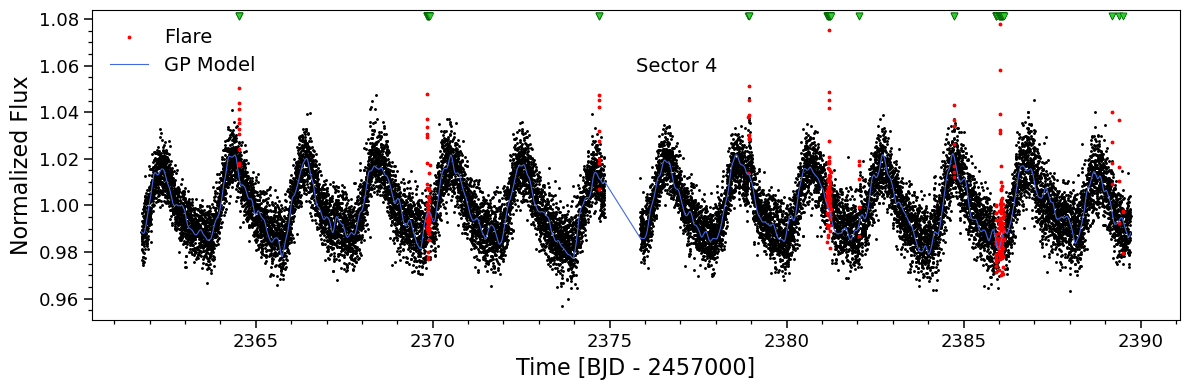

In [21]:
from __future__ import annotations
import matplotlib.pyplot as plt

def _read_dset(ds):
    if ds.shape == () or getattr(ds, "ndim", 0) == 0:
        return ds[()]
    return ds[...]


def plot_sector_light_curve(file_group, title):
    g = file_group
    lc_time = np.array(_read_dset(g["lc_time"]), dtype=float)
    lc_flux = np.array(_read_dset(g["lc_flux"]), dtype=float)
    flux_norm = lc_flux / np.nanmean(lc_flux)

    flare_mask = np.zeros_like(lc_time, dtype=bool)
    if "flare_mask" in g:
        flare_mask = np.array(_read_dset(g["flare_mask"]), dtype=bool)

    gp = None
    if "mu" in g:
        gp = np.array(_read_dset(g["mu"]), dtype=float)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.scatter(lc_time, flux_norm, s=1.2, color="black", rasterized=True)

    if flare_mask.shape == lc_flux.shape and np.any(flare_mask):
        flare_times = lc_time[flare_mask]
        flare_flux = flux_norm[flare_mask]
        ax.scatter(flare_times, flare_flux, s=3, color="red", label="Flare")
        ax.scatter(
            flare_times,
            np.full(flare_times.shape, 0.98),
            transform=ax.get_xaxis_transform(),
            marker="v",
            s=24,
            color="limegreen",
            edgecolors="darkgreen",
            linewidths=0.4,
            alpha=0.9,
            zorder=6,
            rasterized=True,
        )

    if gp is not None and len(gp) == len(lc_time):
        ax.plot(lc_time, gp / np.nanmean(lc_flux), color="royalblue", linewidth=0.8, label="GP Model", rasterized=True)

    ax.text(
        0.575,
        0.85,
        title,
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=14,
        zorder=7,
    )
    ax.set_xlabel("Time [BJD - 2457000]", fontsize=16)
    ax.set_ylabel("Normalized Flux", fontsize=16)
    ax.tick_params(axis="both", which="major", labelsize=13, length=6, width=1.1)
    ax.tick_params(axis="both", which="minor", length=3, width=0.9)
    ax.legend(loc="upper left", fontsize=14, frameon=False)
    ax.minorticks_on()
    plt.tight_layout()
    plt.show()


with h5py.File(h5_path, "r") as f:
    Sector4_Group = f["Sectors"]["sector_4_lc"]

    plot_sector_light_curve(Sector4_Group, title="Sector 4")

Sweet. Those look like some flares! But now what if we want to plot the 6-panel diagnostic Figure for this star?

Well, luckily for us, we make a .py file, that does just this! We can simply load it in, and run it. 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


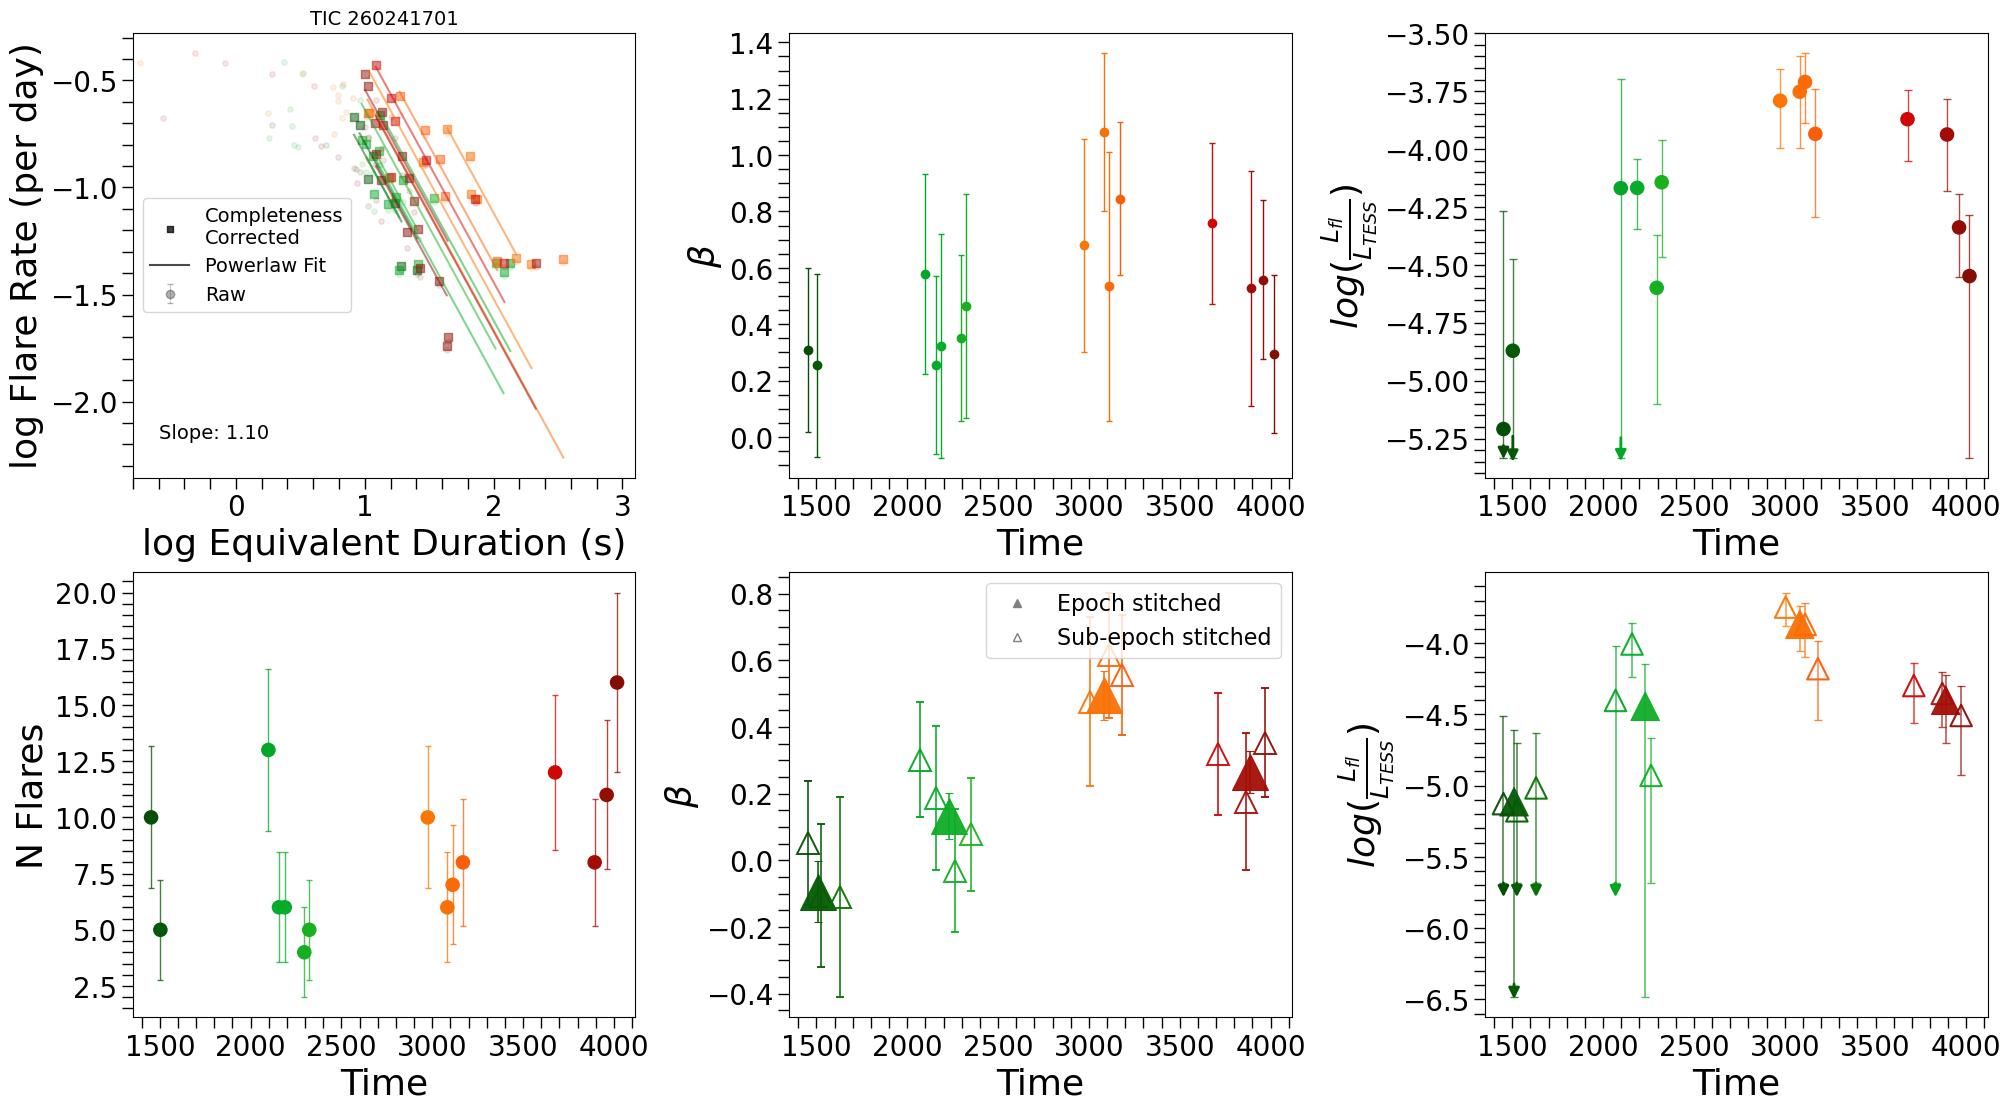

In [31]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from make_6_panel_diagnostic_plot import load_fillin_plot_inputs, make_diagnostic_plot

h5_path = Path("/Users/tobinw/Dropbox/Stellar_Flares_Project/CVZ/Cycle7_Fillin_Results/17_Candidates_Files/tic260241701_final_output_Cycle7_Fillin.h5")

inputs = load_fillin_plot_inputs(h5_path)

make_diagnostic_plot(
    **inputs,
    output_path=None,
    cmap_name="cycle7",
    show=True,
)

If we wanted to do this for all a bunch of tics at one, we just have to iterate over the files. For example, to produce the figures in the other folder of this repo, we can:

In [32]:
from pathlib import Path

from make_6_panel_diagnostic_plot import load_fillin_plot_inputs, make_diagnostic_plot

input_dir = Path("/Users/tobinw/Dropbox/Stellar_Flares_Project/CVZ/Cycle7_Fillin_Results/17_Candidates_Files")
output_dir = Path("../Figures/Candidates")

output_dir.mkdir(parents=True, exist_ok=True)

h5_files = sorted(input_dir.glob("tic*_final_output_Cycle7_Fillin.h5"))

for h5_path in h5_files:
    inputs = load_fillin_plot_inputs(h5_path)

    fig_path = make_diagnostic_plot(
        **inputs,
        output_path=output_dir,
        cmap_name="cycle7",
        show=False,
    )

    # Rename from the script's default output name to tic{x}.pdf
    short_fig_path = output_dir / f"tic{inputs['tic_id']}.pdf"
    fig_path.rename(short_fig_path)

    print(f"Saved {short_fig_path}")

Saved ../Figures/Candidates/tic140758953.pdf
Saved ../Figures/Candidates/tic167344043.pdf
Saved ../Figures/Candidates/tic229783705.pdf
Saved ../Figures/Candidates/tic25132999.pdf
Saved ../Figures/Candidates/tic260241701.pdf
Saved ../Figures/Candidates/tic260506296.pdf
Saved ../Figures/Candidates/tic278901079.pdf
Saved ../Figures/Candidates/tic300866996.pdf
Saved ../Figures/Candidates/tic307986889.pdf
Saved ../Figures/Candidates/tic31381302.pdf
Saved ../Figures/Candidates/tic350520348.pdf
Saved ../Figures/Candidates/tic353898013.pdf
Saved ../Figures/Candidates/tic364588501.pdf
Saved ../Figures/Candidates/tic382575967.pdf
Saved ../Figures/Candidates/tic382624902.pdf
Saved ../Figures/Candidates/tic38827910.pdf
Saved ../Figures/Candidates/tic55453391.pdf
